# 1. Generate the dataset and train locally

Dead plate detection on a can line: classify a top-down image of a conveyor section as `normal` or `fallen_can`.
Everything here is synthetic and deterministic. The flow in `flows/train_flow.py` calls the same functions in the same order,
so only the steps and decorators differ.

In [1]:
import json
from pathlib import Path

import pandas as pd

from candetect.data import DataConfig, generate_dataset, make_splits, write_preview
from candetect.export import check_parity, export_onnx
from candetect.model import weights_to_bytes
from candetect.train import TrainConfig, train

OUT = Path("../artifacts/local")
OUT.mkdir(parents=True, exist_ok=True)

## Dataset

2,000 images at 128x128 from a fixed seed. The content hash identifies this exact data version.

In [2]:
data_config = DataConfig()  # n_images=2000, size=128, seed=7
data = generate_dataset(data_config)
splits = make_splits(data.labels, seed=data_config.seed)
print("images:", data.images.shape, " fallen share:", data.labels.mean())
print("dataset sha256:", data.sha256)
print("split sizes:", {k: len(v) for k, v in vars(splits).items()})
write_preview(data, str(OUT / "preview.png"))

images: (2000, 128, 128, 3)  fallen share: 0.5
dataset sha256: ced936f2033808af0715c636ebf61d8c650fba793d44902618eb0a08d857bc02
split sizes: {'train': 1400, 'val': 300, 'test': 300}


'../artifacts/local/preview.png'

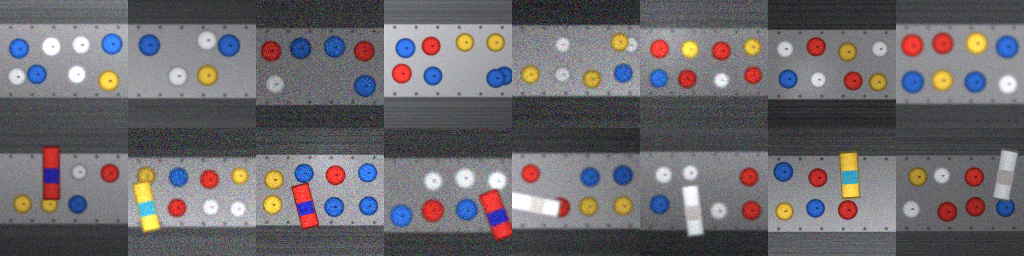

In [3]:
from IPython.display import Image
Image(str(OUT / "preview.png"))

## Train

Fine-tunes torchvision MobileNetV3-Small. If the ImageNet weights cannot be downloaded the code falls back to a small CNN trained from scratch and says so.

In [4]:
train_config = TrainConfig()
result = train(data, splits, train_config)

arch=mobilenet_v3_small pretrained=True device=cpu


epoch 1/6 loss=0.2210 val_f1=0.8889


epoch 2/6 loss=0.0304 val_f1=0.9761


epoch 3/6 loss=0.0154 val_f1=0.9399


epoch 4/6 loss=0.0054 val_f1=0.9967


epoch 5/6 loss=0.0016 val_f1=0.9967


epoch 6/6 loss=0.0016 val_f1=0.9967


test f1=0.9899 accuracy=0.9900


## Evaluate on the held-out test split

In [5]:
print("architecture:", result.arch, "| pretrained:", result.pretrained, "| fallback used:", result.fallback_used)
print(pd.Series(result.test_metrics).round(4).to_string())
pd.DataFrame(
    result.confusion_matrix,
    index=["true normal", "true fallen_can"],
    columns=["pred normal", "pred fallen_can"],
)

architecture: mobilenet_v3_small | pretrained: True | fallback used: False
accuracy       0.9900
precision      1.0000
recall         0.9800
f1             0.9899
n            300.0000


,pred normal,pred fallen_can
true normal,150,0
true fallen_can,3,147


## Save weights (safetensors) and export one self-contained ONNX file

The check compares PyTorch and onnxruntime logits on real test images.

In [6]:
weights = weights_to_bytes(result.model, {"dataset_sha256": data.sha256})
onnx_bytes = export_onnx(result.model)
parity = check_parity(result.model, onnx_bytes, data.images[splits.test][:64])
print("onnx parity:", parity.to_dict())
assert parity.passed

(OUT / "model.safetensors").write_bytes(weights)
(OUT / "model.onnx").write_bytes(onnx_bytes)
(OUT / "summary.json").write_text(json.dumps({
    "dataset_sha256": data.sha256,
    "metrics": result.test_metrics,
    "confusion_matrix": result.confusion_matrix,
    "arch": result.arch,
    "onnx_parity": parity.to_dict(),
}, indent=2))
print({p.name: f"{p.stat().st_size / 1e6:.1f} MB" for p in OUT.glob("model.*")})

[torch.onnx] Obtain model graph for `CanClassifier([...]` with `torch.export.export(..., strict=False)`...


[torch.onnx] Obtain model graph for `CanClassifier([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


onnx parity: {'max_abs_diff': 3.62396240234375e-05, 'argmax_agreement': 1.0, 'atol': 0.001, 'passed': True}
{'model.safetensors': '6.2 MB', 'model.onnx': '6.4 MB'}


Next: the same logic as a Metaflow flow, `make run-remote`.